# Working with Spatial Data in Python — Vector Data
**John Fay · Fall 2026**  


## Highlights

- Vector data represent spatial features as **geometries**: points, lines, and polygons.
  - *Point* = single coordinate pair
  - *Line* = sequence of coordinate pairs
  - *Polygon* = sequence of coordinate pairs, with the last overlapping the first.
- Geometries are stored as coordinate pairs in their own column in a **GeoDataFrame**.
- Geometries and spatial dataframes are also associated with a **coordinate reference system** (crs)
  - The crs defines origin and axes to which the coordinate pairs are referenced.
  - A crs can be geographic and use angular units (e.g. latitude/longitude) ;\
    Or it can be projected and use linear units (e.g. UTM, State Plane)

By the end, you should be able to create points from a table, inspect their CRS, display an interactive map, and attach county attributes using a spatial join.

**Geopandas Documentation**: <https://geopandas.org/en/latest/index.html>

## 1. Prepare your environment and workspace
In a Miniforge terminal, create an environment once:
```bash
conda create -n env700-vector -c conda-forge python=3.12 geopandas pandas matplotlib folium mapclassify jupyterlab ipykernel
```
Open this notebook in VS Code and select **Python (env700-vector)** using **Select Kernel**. 


In [1]:
#Packages for working with data files/remote data
from pathlib import Path
from urllib.request import urlopen
import platform

#Packages for working with data
import pandas as pd
import geopandas as gpd

#Packages for viewing data
import matplotlib.pyplot as plt
import folium
from IPython.display import display

### Locate the project folders

In [2]:
#Paths
PROJECT_ROOT = Path.cwd().parent
raw_folder = PROJECT_ROOT / "Data" / "raw"
processed_folder = PROJECT_ROOT / "Data" / "processed"
print("Project folder:", PROJECT_ROOT)
print("Raw data folder:", raw_folder)

Project folder: /Users/matthewswire/Desktop/Duke/Fall_2026/Data_Exploration/SchroderSwireYangThieu
Raw data folder: /Users/matthewswire/Desktop/Duke/Fall_2026/Data_Exploration/SchroderSwireYangThieu/Data/raw


### Optional: locate Box Drive

In [3]:
#Determine if using a PC, Mac, or Unix
system = platform.system()
if system == "Darwin":
    box_path = Path.home() / "Library" / "CloudStorage" / "Box-Box"
elif system == "Windows":
    box_path = Path.home() / "Box"
else:
    box_path = None

#Report results
if box_path is None:
    print("No Box Drive path configured for this operating system.")
else:
    print("Candidate Box path:", box_path)
    print("Folder exists:", box_path.exists())

Candidate Box path: /Users/matthewswire/Library/CloudStorage/Box-Box
Folder exists: True


## 2. Reading in spatial Data

### 2.1 Converting a dataframe with coordinate data into a GeoDataFrame
If your dataframe has coordinate data, i.e., columns for X and Y coordinates, you can create a column of geospatial point objects, called a **GeoSeries**, from these coordiate column using GeoPandas' `points_from_xy()` function. Once created, you can then create a GeoPandas **GeoDataFrame** from your original dataframe along with this GeoSeries object.

Here we read in the `NWIS_SiteInfo_NE_RAW.csv` file, which has an "x" (`dec_long_va`) and a "y" (`dec_lat_va`) column. We then create the GeoSeries object from these coordinate columns, and from that construct our GeoDataFrame via GeoPandas' `GeoDataFrame()` function.

Note we have to also provide the **coordinate reference system (crs)**. We do so by providing its **EPSG code**; our data has coordinates that are latitude/longitude, so we use the EPSG code of **4326** which represents the World Geodetic Survey of 1984. (See <https://epsg.io/>), often used for data with latitude/longitude coordinates. 

### 2.1 Read the NWIS site table with Pandas. 

In [5]:
#Set the filename
NWIS_filename = raw_folder / "NWIS_SiteInfo_NE_RAW.csv"

#Read the file into a dataframe
NWIS_df = pd.read_csv(NWIS_filename, dtype={"site_no": "string"})

#Display
NWIS_df.head()

,site_no,station_nm,site_tp_cd,dec_lat_va,dec_long_va,coord_acy_cd,dec_coord_datum_cd
0,06453600,"Ponca Creek at Verdel, Nebr.",ST,42.811111,-98.175833,S,NAD83
1,06454100,"Niobrara River at Agate, Nebr.",ST,42.423611,-103.792222,S,NAD83
2,06461500,"Niobrara River near Sparks, Nebr.",ST,42.902222,-100.362222,S,NAD83
3,06463500,"Long Pine Creek near Riverview, Nebr.",ST,42.689444,-99.678889,S,NAD83
4,06463720,"Niobrara River at Mariaville, Nebr.",ST,42.780556,-99.339722,S,NAD83


In [7]:
#Create the GeoSeries object from the coordinate columns
the_geoseries = gpd.points_from_xy(
        x= NWIS_df["dec_long_va"], 
        y= NWIS_df["dec_lat_va"]
    )

#Construct a geodataframe from the dataframe and geoseries, specifying the crs
NWIS_gdf = gpd.GeoDataFrame(
    data = NWIS_df,
    geometry= the_geoseries,
    crs="EPSG:4326"
)

#Display - notice the geometry column 
NWIS_gdf.head()

,site_no,station_nm,site_tp_cd,dec_lat_va,dec_long_va,coord_acy_cd,dec_coord_datum_cd,geometry
0,06453600,"Ponca Creek at Verdel, Nebr.",ST,42.811111,-98.175833,S,NAD83,POINT (-98.17583 42.81111)
1,06454100,"Niobrara River at Agate, Nebr.",ST,42.423611,-103.792222,S,NAD83,POINT (-103.79222 42.42361)
2,06461500,"Niobrara River near Sparks, Nebr.",ST,42.902222,-100.362222,S,NAD83,POINT (-100.36222 42.90222)
3,06463500,"Long Pine Creek near Riverview, Nebr.",ST,42.689444,-99.678889,S,NAD83,POINT (-99.67889 42.68944)
4,06463720,"Niobrara River at Mariaville, Nebr.",ST,42.780556,-99.339722,S,NAD83,POINT (-99.33972 42.78056)


### 2.3 Viewing GeoDataFrames

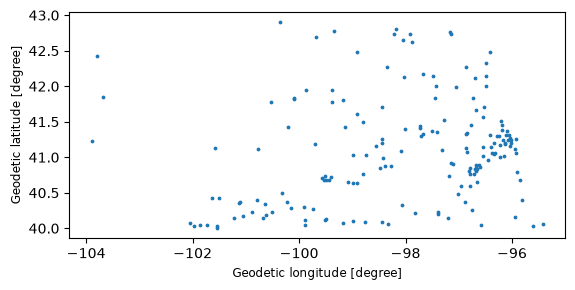

In [12]:
#View as a simple static map
simple_map = NWIS_gdf.plot(markersize=3)
simple_map;

In [13]:
#View as an interactive map (requires internet connection)
NWIS_gdf.explore(tiles="OpenStreetMap")

### 2.3 Reading GeoJSON files directly from the internet

GeoJSON is a text file format that stores all the information of a geospatial feature class: geometries, attributes, and coordinate reference system information. The are text based equivalents of Shapefiles, but since they have all the data in a single file, they are a bit easier to work with. In fact, a web site can host these data on-line and we can read them directly into a spatial dataframe using `st_read()`.

A quick web search for "US Counties GeoJSON" reveals many sources of that dataset. The one that pop up in the result for me is: <https://eric.clst.org/tech/usgeojson/> - an individual who has decided to host many datasets on his personal web site.

The link for US Counties at a 1:5m scale is: [`https://eric.clst.org/assets/wiki/uploads/Stuff/gz_2010_us_050_00_5m.json`](https://eric.clst.org/assets/wiki/uploads/Stuff/gz_2010_us_050_00_5m.json).

We'll fetch that, reading its contents into a spatial dataframe, filtering for just counties in Nebraska, whose state FIPS code is "31".

In [20]:
#Set the URL
counties_url = "https://eric.clst.org/assets/wiki/uploads/Stuff/gz_2010_us_050_00_5m.json"

#Fetch as a geodataframe
counties_gdf = gpd.read_file(counties_url,encoding="ISO-8859-1")

#Filter for Nebraska (FIPS = 31)
counties_gdf = counties_gdf.loc[counties_gdf['STATE']=='31'].reset_index()

#Display as table
counties_gdf.head()

,index,GEO_ID,STATE,COUNTY,NAME,LSAD,CENSUSAREA,geometry
0,444,0500000US31001,31,001,Adams,County,563.272,"POLYGON ((-98.28285 40.69828, -98.2781 40.6982..."
1,445,0500000US31005,31,005,Arthur,County,715.355,"POLYGON ((-101.98463 41.39471, -101.98552 41.7..."
2,446,0500000US31009,31,009,Blaine,County,710.874,"POLYGON ((-99.68683 41.74033, -100.00041 41.73..."
3,447,0500000US31017,31,017,Brown,County,1221.333,"POLYGON ((-100.1676 42.08585, -100.16754 42.43..."
4,448,0500000US31029,31,029,Chase,County,894.419,"POLYGON ((-101.34536 40.69809, -101.34279 40.3..."


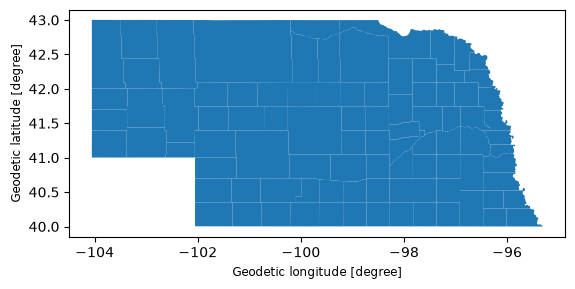

In [21]:
#Display as map
counties_gdf.plot();

## 3. Spatial Operations

### 3.1 Spatial Join
A spatial join assigns values in one dataset based on its overlap with a second spatial dataset. For example, if we wanted to tag each of our NWIS points with the county in which it falls, we would spatially join the county data to the points. This is done via the GeoPandas `sjoin()` function.

In [22]:
#Spatiall join the county attributes to the NWIS points
NWIS_joined = gpd.sjoin(
    left_df = NWIS_gdf,
    right_df = counties_gdf,
    predicate='intersects'
)

#Display info on the result - note the newly added columns
NWIS_joined.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 175 entries, 0 to 174
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   site_no             175 non-null    string  
 1   station_nm          175 non-null    str     
 2   site_tp_cd          175 non-null    str     
 3   dec_lat_va          175 non-null    float64 
 4   dec_long_va         175 non-null    float64 
 5   coord_acy_cd        175 non-null    str     
 6   dec_coord_datum_cd  175 non-null    str     
 7   geometry            175 non-null    geometry
 8   index_right0        175 non-null    int64   
 9   index               175 non-null    int64   
 10  GEO_ID              175 non-null    str     
 11  STATE               175 non-null    str     
 12  COUNTY              175 non-null    str     
 13  NAME                175 non-null    str     
 14  LSAD                175 non-null    str     
 15  CENSUSAREA          175 non-null

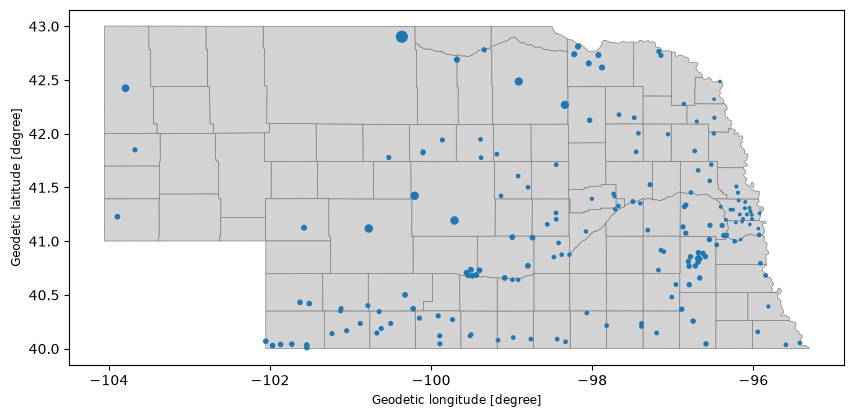

In [23]:
#Plot the result
base_map = counties_gdf.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6))
NWIS_joined.plot(ax=base_map,markersize=NWIS_joined['CENSUSAREA'] / 100);

### 3.2 Spatial Filtering
We can also select features in one spatial dataframe based on its spatial relationship to features in another dataframe, e.g., features in one layer that overlap features in another. The process is analogous to creating a Boolean mask and then subsetting records where that mask is true, except that the Boolean mask is created via a spatial overlay. 

To demonstrate this, we'll extract a subset of NWIS points that overlap a specific watershed, the Platte River [HUC4](https://nas.er.usgs.gov/hucs.aspx), which we can fetch from <https://data.openwaterfoundation.org/country/us/usgs/huc-basins/>. Specifically, the URL for the Platte River HUC4 (1020) data is: https://data.openwaterfoundation.org/country/us/usgs/huc-basins/huc4-basin-1020-platte.geojson

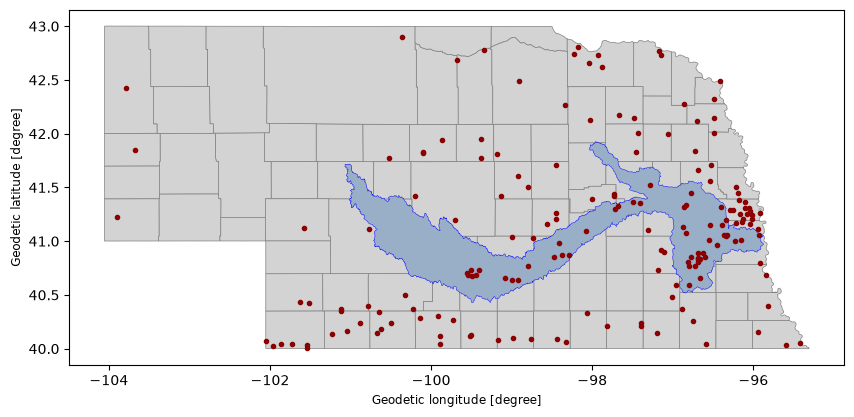

In [24]:
#Fetch the North Platte HUC4 
huc4_url = 'https://data.openwaterfoundation.org/country/us/usgs/huc-basins/huc4-basin-1020-platte.geojson'
huc4_gdf = gpd.read_file(huc4_url) 

#Display the HUC4 with the NWIS points
base_map = counties_gdf.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6))
huc4_gdf.plot(ax=base_map,color='#98AFC7',linewidth=0.3,edgecolor='blue')
NWIS_joined.plot(ax=base_map,markersize=9,color='darkred');

Now, we'll filter the NWIS sites, selecting only those that intersect the features in the Platte River HUC4.

This is done via the `.intersects()` method of the GeoDataFrame. 

**Note** that the argument for the method is a single geometry, not a GeoSeries. Thus we first convert all geometries in the HUC4_gdf into a single geometry by applying the `union_all()` method to the GeoSeries. 

In [25]:
#Create the Boolean mask: True for NWIS points intersecting the Platte River HUC4; false for all others
HUC4_mask = NWIS_gdf.intersects(huc4_gdf['geometry'].union_all()) 

#Filter the NWIS sites that intersect the Platte River HUC4
NWIS_selected = NWIS_gdf[HUC4_mask]

#report how many we selected
print(f'Of the {NWIS_gdf.shape[0]} NWIS points, {NWIS_selected.shape[0]} points fall within the Platte R. HUC4')

Of the 175 NWIS points, 50 points fall within the Platte R. HUC4


> 🔥See the *Geometric Confirmation* section in the GeoPandas cheat sheet for other ways to spatially select features.

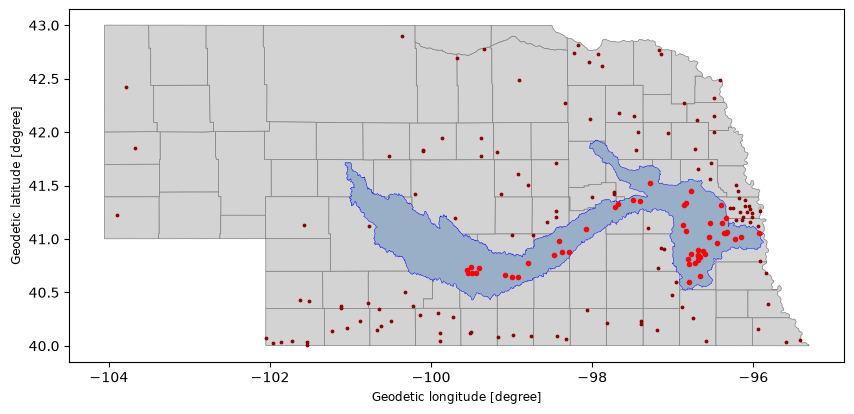

In [26]:
#Display
base_map = counties_gdf.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6)) # County base map
huc4_gdf.plot(ax=base_map,color='#98AFC7',linewidth=0.3,edgecolor='blue')                   # Plot the HUC4
NWIS_joined.plot(ax=base_map,markersize=3,color='darkred')                                    # Plot all the points in darkred
NWIS_selected.plot(ax=base_map,markersize=9,color='red');                                     # Plot the subset points in red

### 3.3 Clipping Features

In addition to spatially selecting features, we can clip features in one spatial dataframe using features in another. Here we'll clip the counties to areas that intersect the Platte River HUC4.

In [27]:
#Clip the counties to the area that falls within the HUC4 polygons
counties_clip = gpd.overlay(
    df1 = counties_gdf, # The layer we want to clip (cookie dough)
    df2 = huc4_gdf,     # The layer used to clip (the cookie cutter)
    how='intersection'  # How we want to clip the data
)

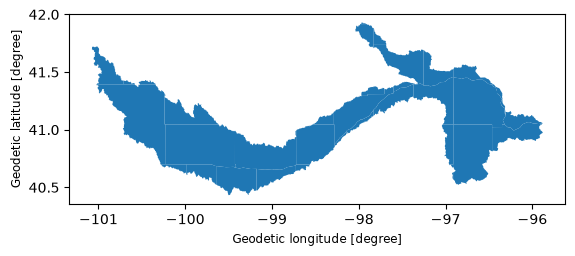

In [28]:
# View the result
counties_clip.plot();

### 3.4 Spatial Aggregation 
The spatial equivalent of grouping and aggregating  (`group_by()` and `.agg()`) is `.dissolve()`. 

Below, we'll first assign a unique value to counties that intersect the Platte R. HUC 4 (using methods described above). Then we'll dissolve the counties dataset to two features: those that intersect the HUC4 and those that don't. 

In [29]:
# Initialize the column values that holds whether the county intersects or doesn't
counties_HUC = counties_gdf.copy()
counties_HUC["InHUC"] = "OUT"

# Create the Boolean mask for counties intersecting HUC4 (as above)
counties_intersect_mask = counties_HUC.intersects(
    huc4_gdf.geometry.union_all()
)

# Update records where mask is True
counties_HUC.loc[counties_intersect_mask, "InHUC"] = "IN"

# Dissolve based on the "InHUC" column
counties_InOut = counties_HUC.dissolve(by="InHUC",aggfunc={'CENSUSAREA':'sum'}).reset_index()
counties_InOut


,InHUC,geometry,CENSUSAREA
0,IN,"POLYGON ((-100.19781 40.35003, -100.75844 40.3...",23651.307
1,OUT,"MULTIPOLYGON (((-101.02769 40.00226, -101.0603...",53172.871


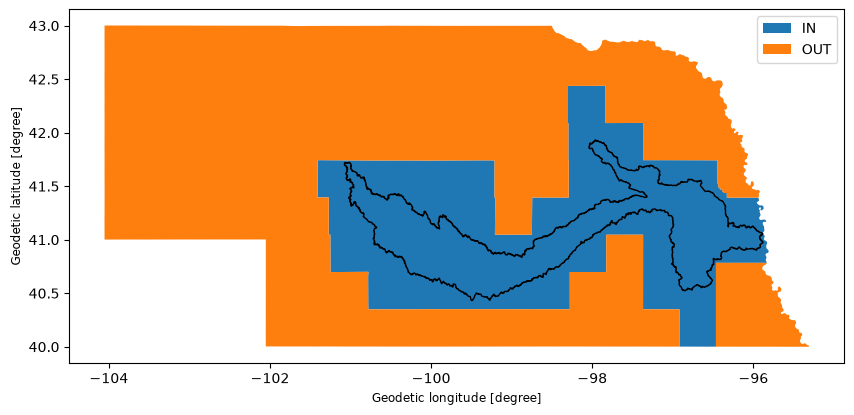

In [30]:
# Show results
base_map = counties_InOut.plot(column="InHUC",legend=True,figsize=(10,6))
huc4_gdf.plot(ax=base_map,facecolor='none',edgecolor='black');

### 3.5 [Geometry manipulations](https://geopandas.org/en/latest/docs/user_guide/geometric_manipulations.html)

We can alter the geometries, i.e., the GeoSeries, in a spatial dataframe. For example, we can buffer features or reduce polygons to their centroids. In doing these calculations, however, we want to ensure our data use a projected coordinate reference system, i.e., one where the x's and y's are in linear units (meters or feet) and not angular units (latitude/longitude).

Without going into gory detail, you'll want to transform your data to a UTM coordinate system. Because we are in Nebraska, we'll use UTM Zone 14N, whose EPSG code is **32614**.

#### 3.5.1 Transforming data to a different CRS
At present, each of our GeoDataFrames uses a **spherical** coordinate system: their geometries use latitude and longitude for coordinates and these are angular measures (degrees). To work more easily with distances, we want to convert or **transform** our GeoDataFrames to use a **planar** coordinate reference system, where coordinates use meters or feet. See GeoPandas documentation on [**projections**])(https://geopandas.org/en/latest/docs/user_guide/projections.html) for more info, but for now, just trust that we want to transform our geographic data to use the UTM Zone 14N crs, which is suited for central Nebraska. And this crs has a [EPSG](https://epsg.io/) code of **32614**.

In [31]:
#Transform each of the geodataframes to a projected coordinate system (EPSG: 32614)
NWIS_utm = NWIS_gdf.to_crs(32614)
counties_utm = counties_gdf.to_crs(32614)
huc4_utm = huc4_gdf.to_crs(32614)

Now that the geometry are in meters, we sensibly perform geometric manipulations. 

Below we provide some examples, with a complete list provided [here](https://geopandas.org/en/latest/docs/user_guide/geometric_manipulations.html). Note that these are all performed on the GeoSeries of the GeoDataframe, i.e., the `geometry` column. 

Here are some examples:

#### 3.5.2 Extracting centroids of polygon features

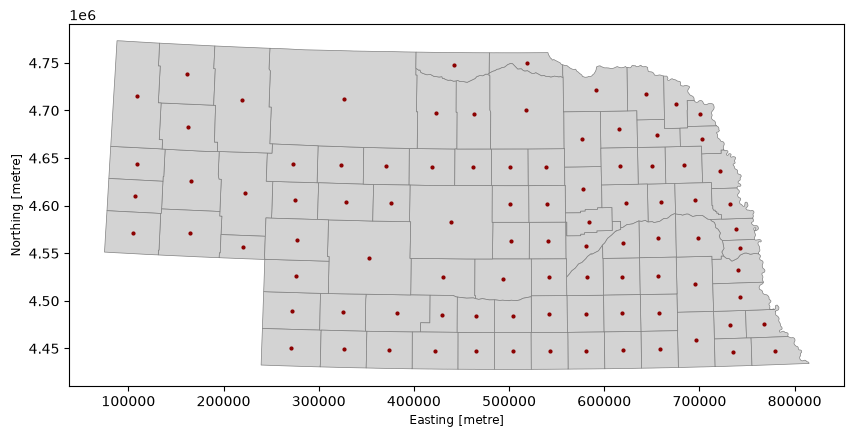

In [32]:
#Extract the centroids of the selected features and show them
county_centroids = counties_utm.copy()
county_centroids['geometry'] = county_centroids.geometry.centroid

#Plot
base_map = counties_utm.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6))
county_centroids.plot(ax=base_map,markersize=4,color='darkred');

#### 3.5.3 Buffering features outwards

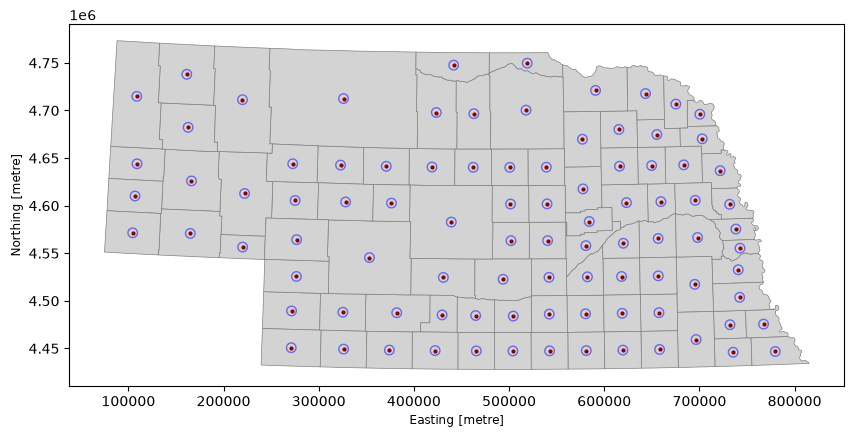

In [33]:
#Buffer the centroids outward 5km and add them to our map
county_centroids_out5km = county_centroids.copy()
county_centroids_out5km['geometry'] = county_centroids_out5km.buffer(5000)

#Plot
base_map = counties_utm.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6))
county_centroids.plot(ax=base_map,markersize=4,color='darkred');
county_centroids_out5km.plot(ax=base_map,markersize=9,facecolor='none',edgecolor='blue',alpha=0.5);


#### 3.5.4 Buffering features inwards

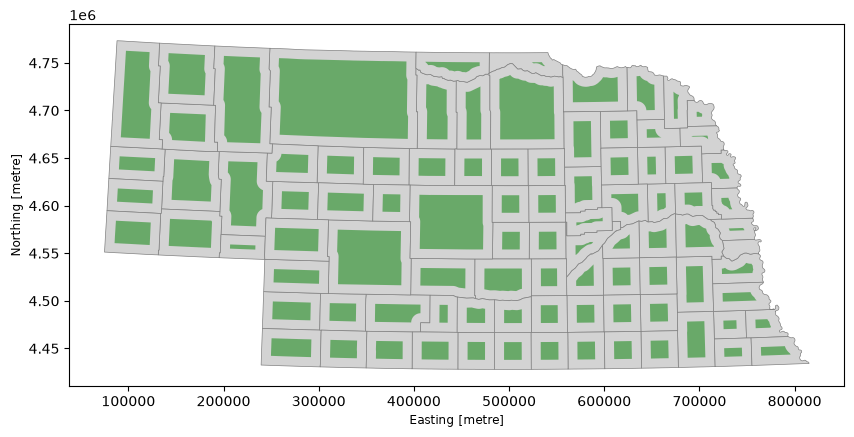

In [34]:
#Buffer the counties inward 10km
counties_in10km = counties_utm.copy()
counties_in10km['geometry'] = counties_in10km.geometry.buffer(-10000)

#Plot
base_map = counties_utm.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6))
counties_in10km.plot(ax=base_map,facecolor='green',edgecolor='none',alpha=0.5);

#### 5.3.5 Convex Hulls
A convex hull is the smallest polygon that encloses all features -- like snapping a rubber band around the features. 

Note that this operation applies to all the geometries (centroid points) collectively, so we need to union them before applying the command. And it only returns one geometry so we create a new dataframe with that one geometry. 

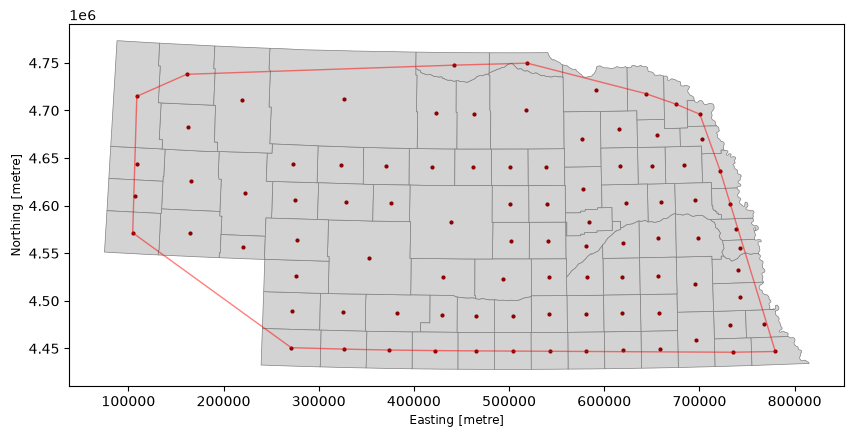

In [35]:
#Construct a convex hull around the centroids
the_convex_hull = county_centroids.geometry.union_all().convex_hull

#Create a new geodataframe to hold the convex hull geometry
county_centroids_chull = gpd.GeoDataFrame(geometry=[the_convex_hull], crs=county_centroids.crs)

#Compute area (in square km) of the convex hull and add it as a new column
county_centroids_chull['Area'] = county_centroids_chull.geometry.area / 1000000

#Plot the convex hull
base_map = counties_utm.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6))
county_centroids.plot(ax=base_map,markersize=4,color='darkred')
county_centroids_chull.plot(ax=base_map,facecolor='none',edgecolor='red',alpha=0.5);

### 4. Distance Calculations

If you want to compute the distance between features in one layer and those of another, we use `sjoin_nearest()`, which is much like a direct spatial join (with `sjoin()`) but joins feature to the nearest feature, in case they don't overlap. 

Here we will assign the information from nearest county centroid to each NWIS point.  

In [36]:
NWIS_utm.head()

,site_no,station_nm,site_tp_cd,dec_lat_va,dec_long_va,coord_acy_cd,dec_coord_datum_cd,geometry
0,06453600,"Ponca Creek at Verdel, Nebr.",ST,42.811111,-98.175833,S,NAD83,POINT (567382.059 4740168.708)
1,06454100,"Niobrara River at Agate, Nebr.",ST,42.423611,-103.792222,S,NAD83,POINT (105720.946 4707948.11)
2,06461500,"Niobrara River near Sparks, Nebr.",ST,42.902222,-100.362222,S,NAD83,POINT (388790.831 4750856.879)
3,06463500,"Long Pine Creek near Riverview, Nebr.",ST,42.689444,-99.678889,S,NAD83,POINT (444386.913 4726552.466)
4,06463720,"Niobrara River at Mariaville, Nebr.",ST,42.780556,-99.339722,S,NAD83,POINT (472211.453 4736502.287)


In [37]:
#Use sjoin_nearest to find the nearest county centorid for each NWIS site
NWIS_nearest_county = NWIS_utm.sjoin_nearest(
    right=county_centroids, 
    how='left',
    distance_col='Distance' #<- Add a column for the distance between features in the two geodataframes
    )

#Reveal the table
NWIS_nearest_county.head()

,site_no,station_nm,site_tp_cd,dec_lat_va,dec_long_va,coord_acy_cd,dec_coord_datum_cd,geometry,index_right0,index,GEO_ID,STATE,COUNTY,NAME,LSAD,CENSUSAREA,Distance
0,06453600,"Ponca Creek at Verdel, Nebr.",ST,42.811111,-98.175833,S,NAD83,POINT (567382.059 4740168.708),69,2301,0500000US31107,31,107,Knox,County,1108.350,30252.960853
1,06454100,"Niobrara River at Agate, Nebr.",ST,42.423611,-103.792222,S,NAD83,POINT (105720.946 4707948.11),83,2350,0500000US31165,31,165,Sioux,County,2066.740,7587.418160
2,06461500,"Niobrara River near Sparks, Nebr.",ST,42.902222,-100.362222,S,NAD83,POINT (388790.831 4750856.879),67,2299,0500000US31103,31,103,Keya Paha,County,773.072,53100.337589
3,06463500,"Long Pine Creek near Riverview, Nebr.",ST,42.689444,-99.678889,S,NAD83,POINT (444386.913 4726552.466),67,2299,0500000US31103,31,103,Keya Paha,County,773.072,21234.283302
4,06463720,"Niobrara River at Mariaville, Nebr.",ST,42.780556,-99.339722,S,NAD83,POINT (472211.453 4736502.287),67,2299,0500000US31103,31,103,Keya Paha,County,773.072,32389.256765


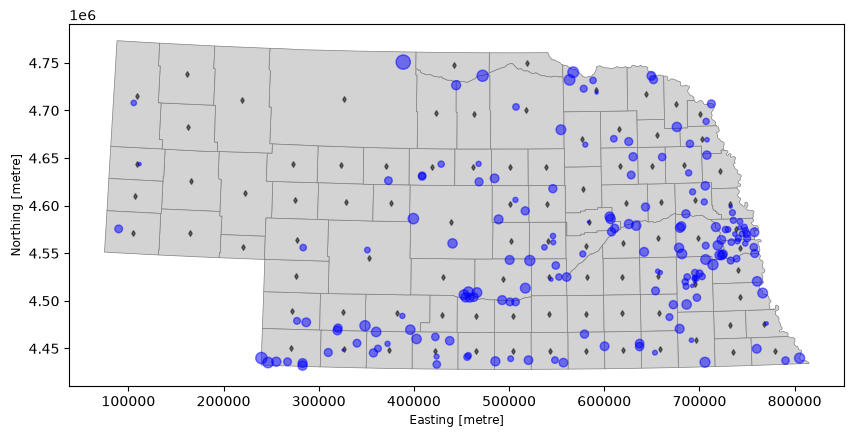

In [38]:
# Plot the NWIS sites sized by distance to nearest county centroid
base_map = counties_utm.plot(color='lightgray',edgecolor='gray',linewidth=0.5,figsize=(10,6))
county_centroids.plot(ax=base_map,markersize=8,color='black',alpha=0.5,marker='d')
NWIS_nearest_county.plot(ax=base_map, markersize=NWIS_nearest_county['Distance']/500, color='blue', alpha=0.5);
